# MRT ridership: exploratory data analysis (EDA)

Goal: understand the raw LTA data **before** cleaning it. This notebook only reads the CSVs
already saved in `data/raw/` (no API calls). Station names, a map and regions come after
steps 4–5, so stations are shown by their **codes** for now.

### The two datasets

| File | What one row means |
|---|---|
| **Station file** (`PV/Train`, `transport_node_train_*.csv`) | At station **X**, during hour **H**, on **weekdays** (or weekends/holidays): how many people **tapped in** (entered) and **tapped out** (exited). |
| **OD file** (`PV/ODTrain`, `origin_destination_train_*.csv`) | **OD = Origin–Destination.** How many trips **started at station A** (origin) and **ended at station B** (destination), where H is the hour the trip **started** (tap-in). |

The station file tells you *how busy* each station is. The OD file tells you *where people go*.

**Two things to remember:**
1. Interchanges are one code, e.g. `NS24/NE6/CC1` = Dhoby Ghaut.
2. **Every number is a monthly total.** "WEEKDAY, 8am" means all the 8:00–8:59 tap-ins added up over *every* weekday in the month.
   A month has about 22 weekdays but only about 8 weekend days, so we divide by the number of days to get **averages per day** before comparing.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap
import pandas as pd

from common import days_by_day_type, latest_raw_month, load_od_raw, load_station_raw

MONTH = latest_raw_month()  # newest month in data/raw/, e.g. '202609'. Change it to look at another month.

# ---- Chart style: quiet background, thin lines, light grid (same for every chart) ----
SURFACE, INK, INK_2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
BLUE, ORANGE, RED, NEUTRAL = "#2a78d6", "#eb6834", "#e34948", "#f0efec"
VIOLET, AQUA = "#4a3aa7", "#1baf7a"

DAY_COLORS = {"WEEKDAY": BLUE, "WEEKENDS/HOLIDAY": ORANGE}   # weekday is always blue, weekend always orange
DAY_LABELS = {"WEEKDAY": "Weekday", "WEEKENDS/HOLIDAY": "Weekend / holiday"}
TAP_COLORS = {"tap in": VIOLET, "tap out": AQUA}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK_2,
    "axes.titlesize": 12, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "lines.solid_capstyle": "round",
    "legend.frameon": False, "figure.dpi": 110,
})

def k_format(x, _pos=None):
    # 1234 -> '1.2k', 250000 -> '250k', 1500000 -> '1.5M'
    if abs(x) >= 1e6:
        return f"{x / 1e6:.1f}M"
    if abs(x) >= 1e3:
        return f"{x / 1e3:.0f}k"
    return f"{x:.0f}"

# Trains run from about 5:30am to just after midnight; there are no taps from 1am to 4:59am.
# To draw one operating day left-to-right we put midnight (hour 0) AFTER 11pm, at x = 24.
def service_hour(h):
    return 24 if h == 0 else h

HOUR_TICKS = [6, 9, 12, 15, 18, 21, 24]
HOUR_LABELS = ["6am", "9am", "12pm", "3pm", "6pm", "9pm", "12am"]

def hour_axis(ax):
    ax.set_xticks(HOUR_TICKS, HOUR_LABELS)
    ax.set_xlim(4.5, 24.5)
    ax.grid(axis="x", visible=False)

## 1. Load the data and add "per day" columns

In [2]:
station = load_station_raw(MONTH)
od = load_od_raw(MONTH)

DAYS = days_by_day_type(MONTH)
print(f"Month {MONTH}: {DAYS}")

# Divide each monthly total by the number of days of that type -> average per day
station["tap_in_per_day"] = station["TOTAL_TAP_IN_VOLUME"] / station["DAY_TYPE"].map(DAYS)
station["tap_out_per_day"] = station["TOTAL_TAP_OUT_VOLUME"] / station["DAY_TYPE"].map(DAYS)
od["trips_per_day"] = od["TOTAL_TRIPS"] / od["DAY_TYPE"].map(DAYS)

print(f"Station file: {len(station):,} rows, {station['PT_CODE'].nunique()} stations")
print(f"OD file:      {len(od):,} rows, "
      f"{od[['ORIGIN_PT_CODE', 'DESTINATION_PT_CODE']].drop_duplicates().shape[0]:,} station pairs")
station.head()

Month 202609: {'WEEKDAY': 22, 'WEEKENDS/HOLIDAY': 8}
Station file: 7,376 rows, 185 stations
OD file:      887,478 rows, 32,048 station pairs


,YEAR_MONTH,DAY_TYPE,TIME_PER_HOUR,PT_TYPE,PT_CODE,TOTAL_TAP_IN_VOLUME,TOTAL_TAP_OUT_VOLUME,tap_in_per_day,tap_out_per_day
0,2026-09,WEEKENDS/HOLIDAY,15,TRAIN,TE6,3843,4363,480.375000,545.375000
1,2026-09,WEEKDAY,14,TRAIN,NE14,26973,26132,1226.045455,1187.818182
2,2026-09,WEEKDAY,10,TRAIN,SE2,6690,3002,304.090909,136.454545
3,2026-09,WEEKENDS/HOLIDAY,6,TRAIN,EW27,11867,6678,1483.375000,834.750000
4,2026-09,WEEKENDS/HOLIDAY,19,TRAIN,EW25,9116,10933,1139.500000,1366.625000


In [3]:
od.head()

,YEAR_MONTH,DAY_TYPE,TIME_PER_HOUR,PT_TYPE,ORIGIN_PT_CODE,DESTINATION_PT_CODE,TOTAL_TRIPS,trips_per_day
0,2026-09,WEEKENDS/HOLIDAY,6,TRAIN,EW12/DT14,DT7,14,1.750000
1,2026-09,WEEKDAY,11,TRAIN,TE4,CC11,7,0.318182
2,2026-09,WEEKDAY,14,TRAIN,CC24,PE1,18,0.818182
3,2026-09,WEEKENDS/HOLIDAY,6,TRAIN,PE6,SW7,2,0.250000
4,2026-09,WEEKENDS/HOLIDAY,12,TRAIN,EW20,NS17/CC15,6,0.750000


## 2. Weekday vs weekend: why we need averages per day

A table is clearer than a chart here: it's just a few numbers.

In [4]:
summary = station.groupby("DAY_TYPE")[["TOTAL_TAP_IN_VOLUME"]].sum()
summary["days_in_month"] = summary.index.map(DAYS)
summary["tap_ins_per_day"] = summary["TOTAL_TAP_IN_VOLUME"] / summary["days_in_month"]
summary.index = summary.index.map(DAY_LABELS)

ratio_total = summary["TOTAL_TAP_IN_VOLUME"].iloc[0] / summary["TOTAL_TAP_IN_VOLUME"].iloc[1]
ratio_day = summary["tap_ins_per_day"].iloc[0] / summary["tap_ins_per_day"].iloc[1]
print(f"Monthly totals: weekdays look {ratio_total:.1f}x busier than weekends")
print(f"Per day:        weekdays are really {ratio_day:.2f}x busier")
summary.style.format("{:,.0f}")

Monthly totals: weekdays look 3.5x busier than weekends
Per day:        weekdays are really 1.27x busier


,TOTAL_TAP_IN_VOLUME,days_in_month,tap_ins_per_day
DAY_TYPE,,,
Weekday,"67,641,976",22,"3,074,635"
Weekend / holiday,"19,409,461",8,"2,426,183"


## 3. How does ridership change hour by hour?

All stations added together: average tap-ins per day in each hour.

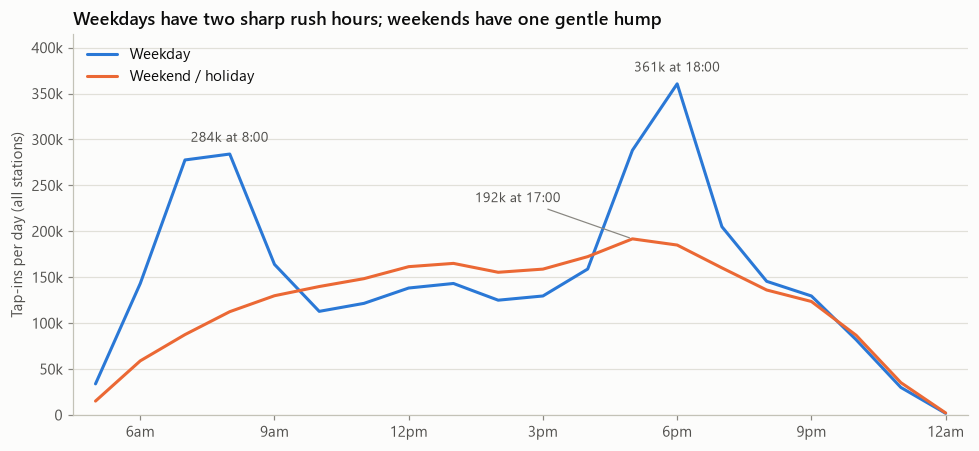

In [5]:
hourly = station.groupby(["DAY_TYPE", "TIME_PER_HOUR"])["tap_in_per_day"].sum().reset_index()
hourly["x"] = hourly["TIME_PER_HOUR"].map(service_hour)

def label_peak(ax, rows, offset=(0, 8), leader=False):
    # Write "value at hour" above the highest point in `rows`.
    # leader=True draws a thin line to the point, for labels moved away to avoid other lines.
    peak = rows.loc[rows["tap_in_per_day"].idxmax()]
    ax.annotate(f"{k_format(peak['tap_in_per_day'])} at {int(peak['TIME_PER_HOUR'])}:00",
                (peak["x"], peak["tap_in_per_day"]), xytext=offset, textcoords="offset points",
                ha="center", fontsize=9, color=INK_2,
                arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8) if leader else None)

fig, ax = plt.subplots(figsize=(9, 4.2))
for day_type, grp in hourly.groupby("DAY_TYPE"):
    grp = grp.sort_values("x")
    ax.plot(grp["x"], grp["tap_in_per_day"], color=DAY_COLORS[day_type], label=DAY_LABELS[day_type])

# Label only the peaks, not every point
weekday = hourly[hourly["DAY_TYPE"] == "WEEKDAY"]
weekend = hourly[hourly["DAY_TYPE"] == "WEEKENDS/HOLIDAY"]
label_peak(ax, weekday[weekday["TIME_PER_HOUR"].between(6, 10)])     # weekday morning peak
label_peak(ax, weekday[weekday["TIME_PER_HOUR"].between(16, 20)])    # weekday evening peak
label_peak(ax, weekend, offset=(-75, 24), leader=True)               # weekend peak, moved off the blue line

hour_axis(ax)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(k_format))
ax.set_ylim(0, hourly["tap_in_per_day"].max() * 1.15)
ax.set_ylabel("Tap-ins per day (all stations)")
ax.set_title("Weekdays have two sharp rush hours; weekends have one gentle hump")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

**What we see (Sep 2026):**
- Weekdays: a morning rush (7–8am) and an even bigger evening rush at 6pm. The morning rush is spread over two hours; the evening one is squeezed into one.
- Weekends: no rush hour, just a slow build to a peak around 5pm.
- Between 10am and 3pm, weekends are actually **busier than weekdays**.
- Nothing from 1am to 4:59am: trains don't run.

## 4. Which stations are busiest?

Busiest = tap-ins + tap-outs (everyone passing through the gates), averaged per day.
Weekday on the left, weekend on the right, so you can see which stations rise on weekends.

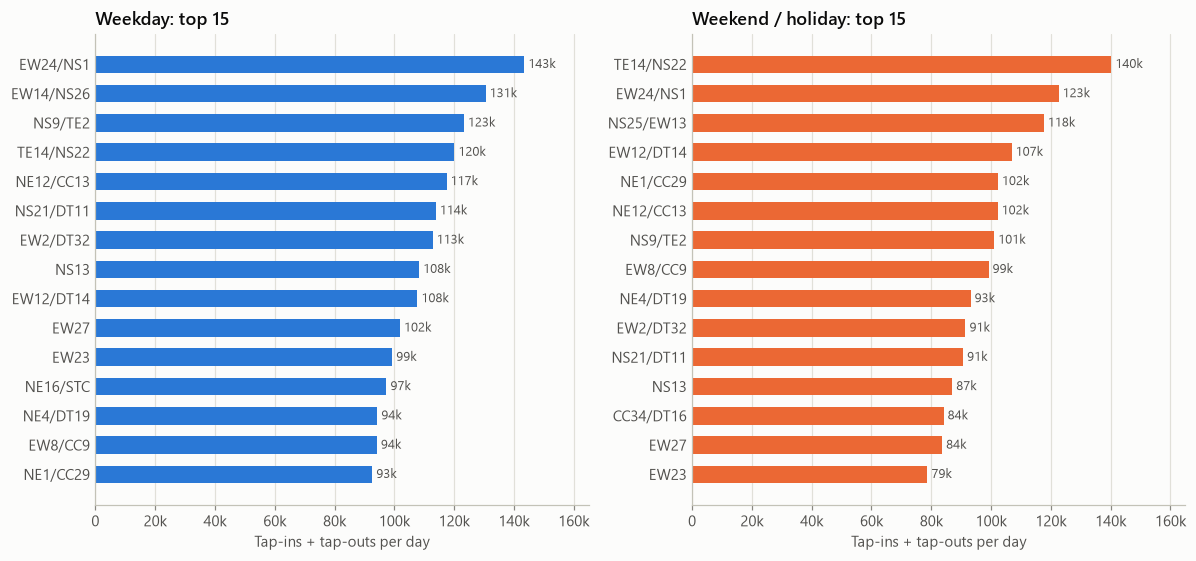

In [6]:
station["volume_per_day"] = station["tap_in_per_day"] + station["tap_out_per_day"]
busy = station.groupby(["DAY_TYPE", "PT_CODE"])["volume_per_day"].sum()

TOP_N = 15
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2), sharex=True)
for ax, day_type in zip(axes, ["WEEKDAY", "WEEKENDS/HOLIDAY"]):
    top = busy[day_type].sort_values().tail(TOP_N)   # sort ascending so the biggest bar is on top
    ax.barh(top.index, top.values, height=0.6, color=DAY_COLORS[day_type])
    for y, value in enumerate(top.values):        # value at the tip of each bar
        ax.text(value, y, f" {k_format(value)}", va="center", fontsize=8.5, color=INK_2)
    ax.set_title(f"{DAY_LABELS[day_type]}: top {TOP_N}")
    ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(k_format))
    ax.set_xlabel("Tap-ins + tap-outs per day")
    ax.tick_params(axis="y", length=0)
axes[1].set_xlim(0, busy.max() * 1.15)
plt.tight_layout()
plt.show()

In [7]:
# Same thing as a table: rank on weekdays vs rank on weekends
ranks = busy.unstack("DAY_TYPE")
ranks["weekday_rank"] = ranks["WEEKDAY"].rank(ascending=False).astype(int)
ranks["weekend_rank"] = ranks["WEEKENDS/HOLIDAY"].rank(ascending=False).astype(int)
ranks["weekend_vs_weekday"] = ranks["WEEKENDS/HOLIDAY"] / ranks["WEEKDAY"]

# Skip very quiet stations: there, a few hundred people can swing the percentage a lot
MIN_PER_DAY = 2000
print("Stations that hold up best on weekends (weekend volume as a share of weekday volume),")
print(f"only stations with at least {MIN_PER_DAY:,} people per weekday:")
ranks[ranks["WEEKDAY"] >= MIN_PER_DAY].sort_values("weekend_vs_weekday", ascending=False).head(10).style.format(
    {"WEEKDAY": "{:,.0f}", "WEEKENDS/HOLIDAY": "{:,.0f}", "weekend_vs_weekday": "{:.0%}"})

Stations that hold up best on weekends (weekend volume as a share of weekday volume),
only stations with at least 2,000 people per weekday:


DAY_TYPE,WEEKDAY,WEEKENDS/HOLIDAY,weekday_rank,weekend_rank,weekend_vs_weekday
PT_CODE,,,,,
TE22,"5,919","11,892",160,96,201%
CC6,"12,508","21,551",118,75,172%
NS28,"3,270","5,567",177,152,170%
CC34/DT16,"63,826","84,116",31,13,132%
NS25/EW13,"89,775","117,641",16,3,131%
CC3,"15,000","19,648",105,78,131%
NE8,"56,812","72,540",42,18,128%
DT22,"20,309","24,484",92,65,121%
NE7/DT12,"54,277","64,385",43,22,119%


**What we see (Sep 2026)** (names added by hand to help reading; official names come in step 5):
- Weekday top 5: `EW24/NS1` Jurong East, `EW14/NS26` Raffles Place, `NS9/TE2` Woodlands, `TE14/NS22` Orchard,
  `NE12/CC13` Serangoon. That's a mix of the CBD and big heartland interchanges.
- Weekend: **Orchard becomes #1**, City Hall (`NS25/EW13`) jumps from #16 to #3, and Raffles Place drops out of the top 15 (offices are closed).
- The stations that hold up best on weekends are leisure spots: Gardens by the Bay (`TE22`, about 2× its weekday volume),
  Stadium (`CC6`), Marina South Pier (`NS28`, ferries), Bayfront (`CC34/DT16`), Esplanade (`CC3`), and the Little India area
  (Farrer Park `NE8`, Jalan Besar `DT22`, Little India `NE7/DT12`).

## 5. Station "personalities": homes vs workplaces

Tap-in and tap-out on a **weekday**, hour by hour, for three stations picked automatically:
- the station where the most people **leave in the morning** (more tap-ins than tap-outs, 7–9am): a home area
- the station where the most people **arrive in the morning** (more tap-outs than tap-ins, 7–9am): a work area
- the **busiest** station overall

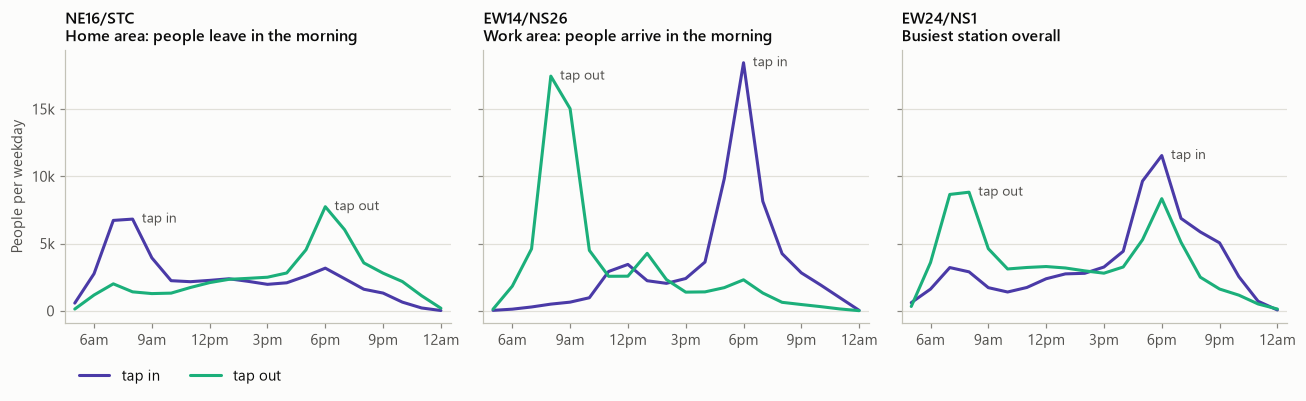

In [8]:
wkday = station[station["DAY_TYPE"] == "WEEKDAY"].copy()
wkday["net_per_day"] = wkday["tap_in_per_day"] - wkday["tap_out_per_day"]   # + = more people leaving from here
wkday["x"] = wkday["TIME_PER_HOUR"].map(service_hour)

morning_net = wkday[wkday["TIME_PER_HOUR"].between(7, 9)].groupby("PT_CODE")["net_per_day"].sum()
home_like = morning_net.idxmax()
work_like = morning_net.idxmin()
busiest = busy["WEEKDAY"].drop([home_like, work_like]).idxmax()
examples = {home_like: "Home area: people leave in the morning",
            work_like: "Work area: people arrive in the morning",
            busiest: "Busiest station overall"}

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, (code, title) in zip(axes, examples.items()):
    one = wkday[wkday["PT_CODE"] == code].sort_values("x")
    for col, name in [("tap_in_per_day", "tap in"), ("tap_out_per_day", "tap out")]:
        ax.plot(one["x"], one[col], color=TAP_COLORS[name], label=name)
        # Direct label at the line's highest point, so colour isn't the only clue
        top = one.loc[one[col].idxmax()]
        ax.annotate(name, (top["x"], top[col]), xytext=(6, 0), textcoords="offset points",
                    va="center", fontsize=9, color=INK_2)
    ax.set_title(f"{code}\n{title}", fontsize=10.5)
    hour_axis(ax)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(k_format))
axes[0].set_ylabel("People per weekday")
axes[0].legend(loc="upper left", bbox_to_anchor=(0, -0.12), ncol=2)
plt.tight_layout()
plt.show()

**What we see (Sep 2026):**
- `NE16/STC` **Sengkang** (home): people tap **in** in the morning (leaving home) and tap **out** in the evening (coming home).
- `EW14/NS26` **Raffles Place** (work): the mirror image. About 17k people arrive at 8am and about 18k leave at 6pm; almost nobody starts a trip there in the morning.
- `EW24/NS1` **Jurong East** (busiest): both patterns at once. It's a regional centre with offices and malls, so more people arrive than leave in the morning.

This is what `net = tap_in − tap_out` will capture in the cleaned data.

## 6. The same idea for the 25 busiest stations: net flow heatmap

Each cell = tap-ins minus tap-outs per weekday.
**Blue** = more people **leaving from** the station (tap in), **red** = more people **arriving** (tap out), grey = balanced.
Rows are sorted by the morning pattern, so home-type stations are at the top and work-type stations at the bottom.

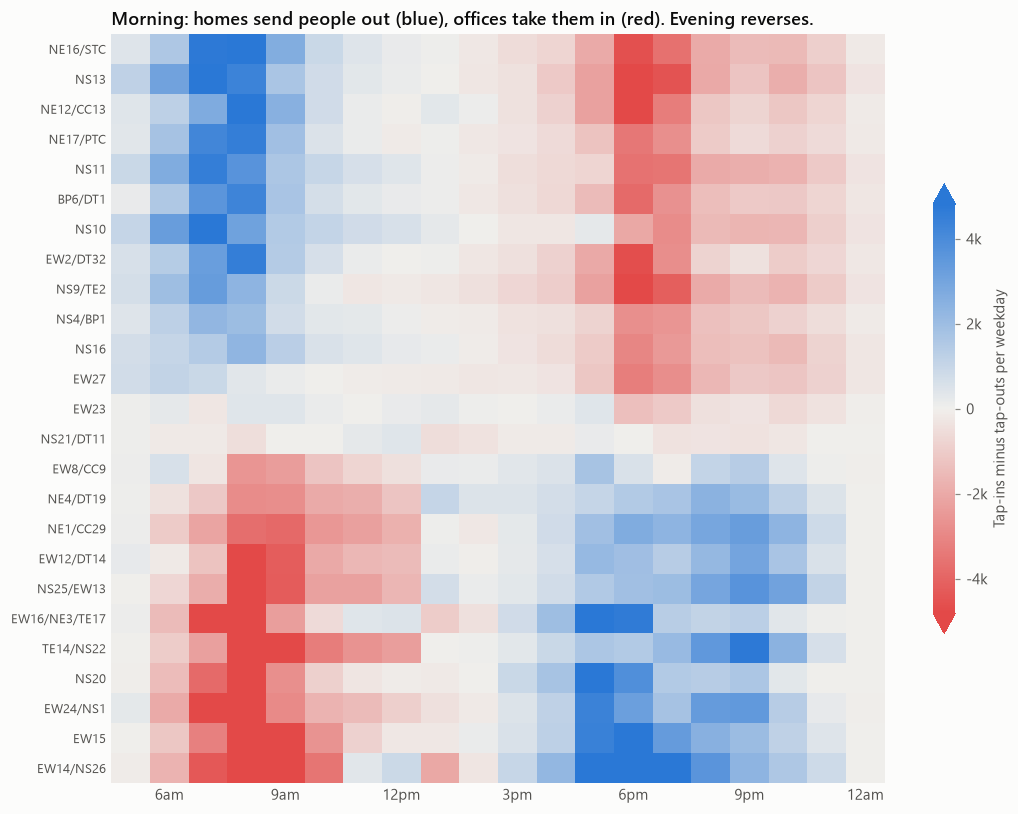

In [9]:
top25 = busy["WEEKDAY"].sort_values(ascending=False).head(25).index
net = (wkday[wkday["PT_CODE"].isin(top25)]
       .pivot_table(index="PT_CODE", columns="x", values="net_per_day", fill_value=0))
net = net.loc[morning_net[top25].sort_values(ascending=False).index]   # sort rows by morning net

limit = net.abs().stack().quantile(0.95)          # colour scale: the strongest 5% of cells just get the darkest colour
diverging = LinearSegmentedColormap.from_list("red_grey_blue", [RED, NEUTRAL, BLUE])

fig, ax = plt.subplots(figsize=(10, 7.5))
im = ax.imshow(net.values, cmap=diverging, vmin=-limit, vmax=limit, aspect="auto")
ax.set_yticks(range(len(net)), net.index, fontsize=8.5)
cols = list(net.columns)
ax.set_xticks([cols.index(h) for h in HOUR_TICKS if h in cols],
              [lab for h, lab in zip(HOUR_TICKS, HOUR_LABELS) if h in cols])
ax.grid(False)
ax.tick_params(length=0)
for side in ["left", "bottom"]:
    ax.spines[side].set_visible(False)
cbar = fig.colorbar(im, ax=ax, shrink=0.6, extend="both", format=mticker.FuncFormatter(k_format))
cbar.set_label("Tap-ins minus tap-outs per weekday")
cbar.outline.set_visible(False)
ax.set_title("Morning: homes send people out (blue), offices take them in (red). Evening reverses.")
plt.tight_layout()
plt.show()

**What we see (Sep 2026):**
- **Top rows (home areas):** Sengkang, Yishun (`NS13`), Serangoon, Punggol (`NE17/PTC`), Sembawang (`NS11`), Bukit Panjang, Admiralty (`NS10`),
  Tampines, Woodlands. They're blue in the morning and red in the evening.
- **Bottom rows (work areas):** Raffles Place, Tanjong Pagar (`EW15`), Novena (`NS20`), Jurong East, Orchard, Outram Park. Red in the morning, blue in the evening.
- **Grey rows** (Clementi `EW23`, Newton `NS21/DT11`) are balanced: mixed homes and jobs, or mostly transfers.
- Orchard stays blue until about 9pm, as shoppers and diners head home later than office workers.

## 7. Where do people travel? Top origin → destination pairs (OD file)

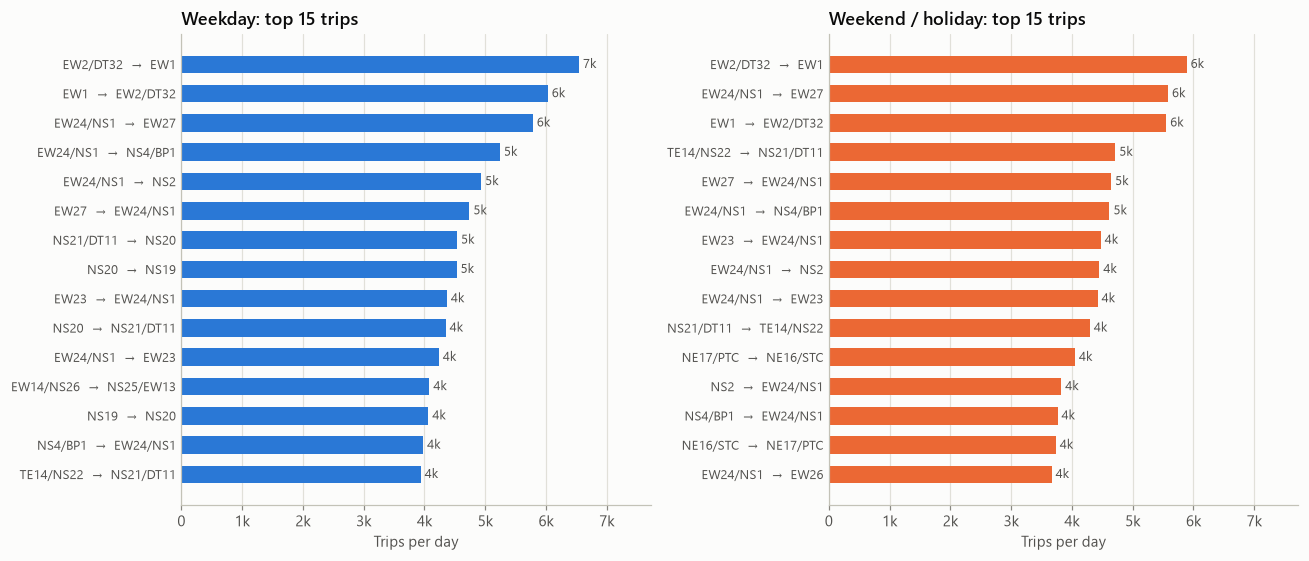

In [10]:
pairs = (od.groupby(["DAY_TYPE", "ORIGIN_PT_CODE", "DESTINATION_PT_CODE"])["trips_per_day"].sum()
           .reset_index())
pairs["pair"] = pairs["ORIGIN_PT_CODE"] + "  →  " + pairs["DESTINATION_PT_CODE"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharex=True)
for ax, day_type in zip(axes, ["WEEKDAY", "WEEKENDS/HOLIDAY"]):
    top = pairs[pairs["DAY_TYPE"] == day_type].nlargest(TOP_N, "trips_per_day").iloc[::-1]
    ax.barh(top["pair"], top["trips_per_day"], height=0.6, color=DAY_COLORS[day_type])
    for y, value in enumerate(top["trips_per_day"]):
        ax.text(value, y, f" {k_format(value)}", va="center", fontsize=8.5, color=INK_2)
    ax.set_title(f"{DAY_LABELS[day_type]}: top {TOP_N} trips")
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0, labelsize=8.5)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(k_format))
    ax.set_xlabel("Trips per day")
axes[1].set_xlim(0, pairs["trips_per_day"].max() * 1.18)
plt.tight_layout()
plt.show()

**What we see (Sep 2026):**
- The busiest trips are **short hops within the same area**, not long commutes into the city: Tampines ↔ Pasir Ris (`EW2/DT32` ↔ `EW1`),
  Jurong East ↔ Boon Lay (`EW27`), Jurong East ↔ Choa Chu Kang (`NS4/BP1`) and Bukit Batok (`NS2`), and Newton ↔ Novena ↔ Toa Payoh (`NS19`).
- Most pairs appear **in both directions**: people go and come back.
- CBD stations are busy (section 4) but don't show up here, because their riders come from all over the island, spread across many pairs.
- Even the top pair is only about 7k trips a day out of about 3 million. No single route dominates.

## 8. How concentrated are the trips?

There are tens of thousands of station pairs. Do a few pairs carry most of the trips,
or is travel spread out? Sort all pairs from busiest to quietest and add up their share.

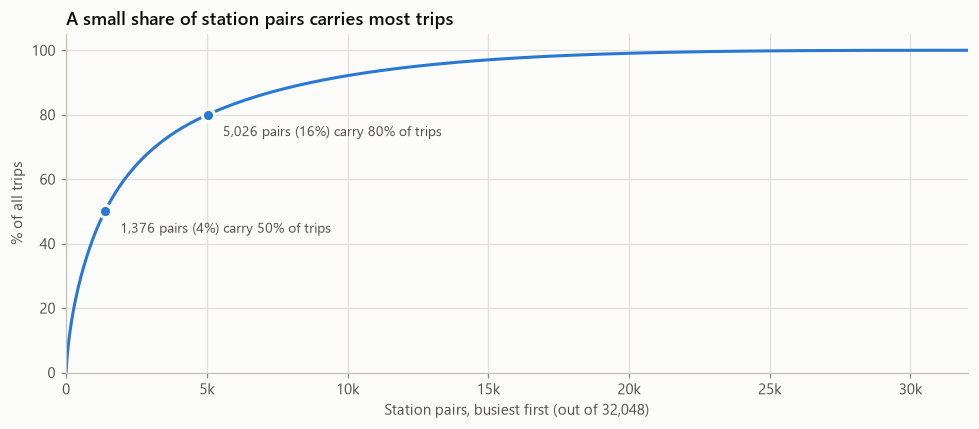

In [11]:
pair_totals = od.groupby(["ORIGIN_PT_CODE", "DESTINATION_PT_CODE"])["TOTAL_TRIPS"].sum().sort_values(ascending=False)
cum_share = pair_totals.cumsum() / pair_totals.sum()
n_pairs = len(pair_totals)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(range(1, n_pairs + 1), cum_share.values * 100, color=BLUE)
for target in [0.5, 0.8]:
    n = int((cum_share < target).sum()) + 1     # pairs needed to reach this share
    ax.plot(n, target * 100, "o", color=BLUE, markersize=8, markeredgecolor=SURFACE, markeredgewidth=2)
    ax.annotate(f"{n:,} pairs ({n / n_pairs:.0%}) carry {target:.0%} of trips", (n, target * 100),
                xytext=(10, -14), textcoords="offset points", fontsize=9, color=INK_2)
ax.set_xlabel(f"Station pairs, busiest first (out of {n_pairs:,})")
ax.set_ylabel("% of all trips")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(k_format))
ax.set_ylim(0, 105)
ax.set_xlim(0, n_pairs)
ax.set_title("A small share of station pairs carries most trips")
plt.tight_layout()
plt.show()

**What we see:** half of all trips run between just ~4% of station pairs, and 80% between ~16%.
The rest is a long tail of pairs with only a few trips a month. For a flow map in the video, we'll want to show only
the top few hundred pairs, or group stations into regions (that's what `od_region.csv` in step 6 is for).

## 9. Do the two files agree?

Every OD trip starts with a tap-in, so for each station, *trips starting here (OD file)* should be close to
*tap-ins (station file)*. Each dot is a station: how many of its tap-ins also appear as an OD trip.

Overall, OD trips = 98.7% of tap-ins
Stations between 97% and 100%: 95%


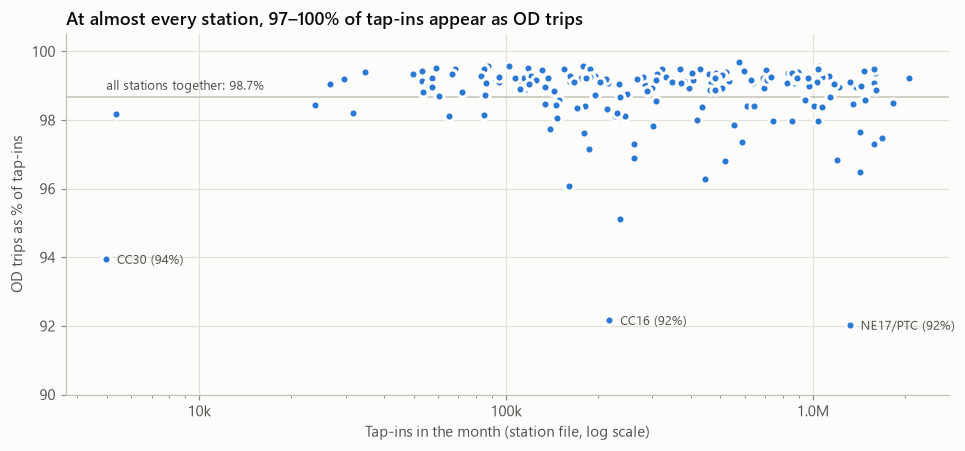

,tap_ins,od_trips_starting_here,ratio
NE17/PTC,"1,320,734","1,215,323",92.0%
CC16,"217,427","200,377",92.2%
CC30,"4,983","4,681",93.9%
CC14,"234,621","223,139",95.1%
CC20,"161,049","154,725",96.1%


In [12]:
check = pd.DataFrame({
    "tap_ins": station.groupby("PT_CODE")["TOTAL_TAP_IN_VOLUME"].sum(),
    "od_trips_starting_here": od.groupby("ORIGIN_PT_CODE")["TOTAL_TRIPS"].sum(),
})
check["ratio"] = check["od_trips_starting_here"] / check["tap_ins"]
overall = check["od_trips_starting_here"].sum() / check["tap_ins"].sum()
print(f"Overall, OD trips = {overall:.1%} of tap-ins")
print(f"Stations between 97% and 100%: {check['ratio'].between(0.97, 1.0).mean():.0%}")

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.axhline(overall * 100, color="#c3c2b7", linewidth=1, zorder=1)
ax.annotate(f"all stations together: {overall:.1%}", (check["tap_ins"].min(), overall * 100),
            xytext=(0, 5), textcoords="offset points", fontsize=8.5, color=INK_2)
ax.scatter(check["tap_ins"], check["ratio"] * 100, s=36, color=BLUE,
           edgecolor=SURFACE, linewidth=2, zorder=2)
for code, row in check.nsmallest(3, "ratio").iterrows():   # label the 3 stations that match worst
    ax.annotate(f"{code} ({row['ratio']:.0%})", (row["tap_ins"], row["ratio"] * 100),
                xytext=(7, -3), textcoords="offset points", fontsize=8.5, color=INK_2)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(k_format))
ax.set_ylim(90, 100.5)
ax.set_xlabel("Tap-ins in the month (station file, log scale)")
ax.set_ylabel("OD trips as % of tap-ins")
ax.set_title("At almost every station, 97–100% of tap-ins appear as OD trips")
plt.tight_layout()
plt.show()

check.sort_values("ratio").head(5).style.format({"tap_ins": "{:,.0f}", "od_trips_starting_here": "{:,.0f}", "ratio": "{:.1%}"})

**What we see:** the two files are consistent, so we can use the station file for "how busy" and the OD file for
"where people go" without them contradicting each other. About 1.3% of tap-ins have no OD trip. The OD file contains
no trips that start and end at the same station, so those (and journeys with no valid exit) are probably left out.
Punggol (`NE17/PTC`) and Marymount (`CC16`) have the largest gaps at about 8%; the validation report in step 7 will look at this.

## 10. What this EDA can't show yet

- **Station names** (we only have codes): step 5 adds them.
- **Maps** (where stations are): need coordinates from step 4.
- **Region-to-region flows** (e.g. North → Central in the morning): need regions from step 5.

For data-quality checks (missing hours, zeros, duplicates), run `python inspect_raw.py`.